# Observe Zigzag oscillation of gradient descent and watch how momentum optimizer alleviates this phenomenon

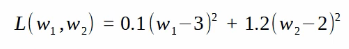

In [63]:
# We visually observe the zigzag oscillation phenomenon
# of gradient descent and verify that the momentum optimizer
# alleviates this phenomenon.
import numpy as np
import tensorflow as tf
from tensorflow.keras import optimizers
import matplotlib.pyplot as plt

In [64]:
# initial point and the target point
w0 = np.array([0.1, 3], dtype='float32')  # initial point
wt = np.array([3, 2], dtype='float32')    # target point
w = tf.Variable(w0)                       # (w1, w2)


## Momentum Optimizer

In [65]:
# opt = optimizers.SGD(learning_rate = 0.8, momentum=0.0) # without momentum - plain SGD
# opt = optimizers.SGD(learning_rate = 0.8, momentum=0.2) # momentum optimizer
# opt = optimizers.Adagrad(learning_rate = 0.8) # adagrad optimizer
opt = optimizers.RMSprop(learning_rate = 0.2, rho=0.1) # rmsprop optimizer

In [66]:
def loss(w):
    return tf.reduce_sum(tf.square(w - wt) * [0.1, 1.2])

path = [w.numpy()]
for i in range(80):
    # perform automatic differentiation
    with tf.GradientTape() as tape:
        # the gradient of w1-axis is small,
        # and the gradient of w2-axis is large.
        dw = tape.gradient(loss(w), [w])

    # update w by gradient descent
    opt.apply_gradients(zip(dw, [w]))
    path.append(w.numpy())

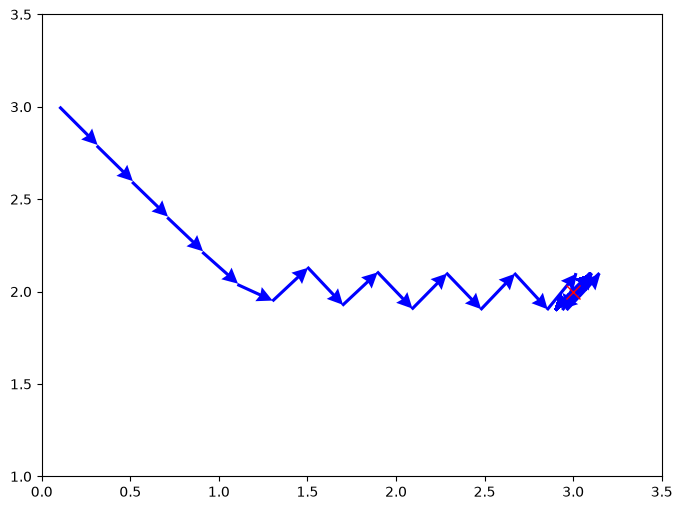

In [67]:
# visually check the path to the optimal point.
path = np.array(path)
x, y = path[:, 0], path[:, 1]
plt.figure(figsize=(8,6))
plt.quiver(x[:-1], y[:-1], x[1:]-x[:-1], y[1:]-y[:-1],
           color='blue', scale_units='xy',
           scale=1, width=0.005, headwidth=5)
plt.plot(wt[0], wt[1], marker='x', markersize=10, color='red')
plt.xlim(0, 3.5)
plt.ylim(1.0, 3.5)
plt.show()

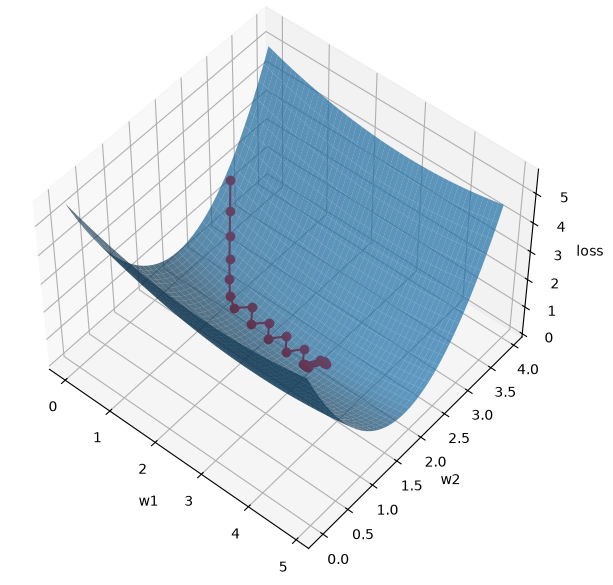

In [68]:
# Draw the loss surface and the path to the optimal point.
w1, w2 = np.meshgrid(np.arange(0, 5, 0.1), np.arange(0, 4, 0.1))
zs = np.array([loss([a,b]).numpy() for [a, b] in zip(np.ravel(w1),
              np.ravel(w2))])
z = zs.reshape(w1.shape)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(w1, w2, z, alpha=0.7)

# Draw the path to the optimal point.
L = np.array([loss([a, b]).numpy() for [a, b] in zip(x, y)])
ax.plot(x, y, L, marker='o', color="r")
ax.set_xlabel('w1')
ax.set_ylabel('w2')
ax.set_zlabel('loss')
ax.azim = -50
ax.elev = 50
plt.show()